# Entrega final — Análisis y clasificación de reseñas de aplicaciones de citas

**Desarrollo de Sistemas de Inteligencia Artificial · Grupo 2**

**Integrantes:** AULAR PUERTA JOSE MIGUEL; PLANES MARIA ANABELLA;  ROMERO SOFIA ALEJANDRA; STANCANELLI CRISTIAN FABIAN.

### GitHub de los integrantes

- AULAR PUERTA JOSE MIGUEL: [https://github.com/](https://github.com/)
- PLANES MARIA ANABELLA: [https://github.com/](https://github.com/)
- ROMERO SOFIA ALEJANDRA: [https://github.com/](https://github.com/)
- STANCANELLI CRISTIAN FABIAN: [https://github.com/24833017-hub/DSIA_StancanelliCristian](https://github.com/24833017-hub/DSIA_StancanelliCristian)

**Dataset elegido:** `dating_app_reviews_sentiment.csv`.

## 1. Problema y objetivo

Analizamos qué tipos y combinaciones de temas detectados se asocian con valoraciones más bajas y cuánto cambian las diferencias entre aplicaciones al comparar una composición temática común. El estudio puede orientar a equipos de producto y experiencia de usuario a identificar diferencias y priorizar la lectura de comentarios. Cada fila representa una reseña, no necesariamente una persona diferente.

Esta entrega integra EDA, limpieza justificada, análisis univariado, bivariado y multivariado, cuatro hipótesis exploratorias con gráficos y conclusiones, y la comparación de tres modelos de clasificación con métricas y selección del modelo.

### Alcance del estudio de satisfacción

El dataset puede abordarse, con fines analíticos, como un conjunto de valoraciones espontáneas de satisfacción: cada registro contiene una puntuación de 1 a 5 estrellas y un comentario libre sobre una aplicación. La puntuación representa la valoración atribuida al usuario en el archivo; el texto permite investigar la experiencia que relata. No son respuestas de satisfacción verificadas por una entrevista independiente.

**No es una encuesta formal:** no contamos con un cuestionario común, diseño muestral ni probabilidades de selección conocidas. Quienes publican reseñas participan por decisión propia, y una fila no necesariamente representa un usuario distinto. No se conocen las opiniones de quienes no publicaron reseñas. Por eso, los porcentajes describen las reseñas disponibles, sin generalizarse al total de clientes o usuarios.

En términos conceptuales, `rating` es una escala ordinal: más estrellas indican una valoración más favorable, pero la distancia subjetiva entre 1 y 2 no necesariamente equivale a la distancia entre 4 y 5. Se priorizan frecuencias, medianas y proporciones, y se presentan medias solo como resúmenes complementarios.

### Estrellas, sentimiento y satisfacción: qué mide cada columna

`rating` contiene la puntuación del usuario y `review_text` su comentario libre. `sentiment` e `is_satisfied` son etiquetas incluidas en el dataset; no hay evidencia de que sean preguntas adicionales respondidas por el usuario ni de que provengan de una lectura independiente del texto.

La auditoría de este archivo verifica la siguiente correspondencia exacta:

| Rating observado | sentiment | is_satisfied | Interpretación operativa |
|---|---|---|---|
| 1 o 2 estrellas | Negative | 0 | Valoración baja |
| 4 o 5 estrellas | Positive | 1 | Valoración alta |
| 3 estrellas | Sin registros | Sin registros | No puede estudiarse la valoración intermedia |

**En este estudio, positivo/negativo y satisfecho/no satisfecho se interpretan como una agrupación de las estrellas, no como evidencia de un análisis semántico independiente del comentario.** La coincidencia no demuestra el procedimiento histórico de generación de las etiquetas. No se conoce por qué faltan las 3 estrellas ni se presupone que fueron eliminadas. Las etiquetas son redundantes respecto de esa agrupación del rating.

Una reseña puede expresar aspectos positivos y negativos a la vez o discrepar con sus estrellas. Su clasificación por rating no equivale a una medición exhaustiva del sentimiento del texto.

### Objetivo del proyecto

**Objetivo general:** analizar las valoraciones de las aplicaciones y sus asociaciones con el contenido de las reseñas, y evaluar la capacidad de tres modelos para clasificar valoraciones altas o bajas usando únicamente el texto.

**Objetivos específicos:**
1. Describir calidad, distribución y cobertura temporal del dataset.
2. Evaluar cuatro hipótesis sobre tipo de tema, acumulación, composición temática por aplicación y combinación de monetización con autenticidad o estafas.
3. Comparar Naive Bayes multinomial, regresión logística y SVM lineal con una línea base mayoritaria, y seleccionar un modelo por F1 macro de validación.
4. Examinar sus errores y límites de aplicación.

Los resultados pueden orientar a equipos de producto y experiencia de usuario en la revisión de comentarios. El análisis descriptivo estudia asociaciones entre temas y valoraciones; la clasificación evalúa cuánto permite el texto anticipar la agrupación de estrellas.

El análisis descriptivo busca comprender asociaciones entre los temas mencionados y las valoraciones. No identifica causas ni confirma la veracidad de lo relatado. La variable objetivo predictiva es `valoracion_alta`: 1 para rating 4–5 y 0 para rating 1–2. No existe clase neutral en este archivo. Se excluyen rating, sentiment, is_satisfied y todas las variables auxiliares de las entradas; se utiliza exclusivamente `review_text`. La predicción no valida el procedimiento de etiquetado ni responde por sí sola las hipótesis temáticas.

### Procedencia y alcance

**Fuente:** *Dating App Reviews: Tinder, Bumble & Hinge*, publicado en Kaggle por la cuenta `samartalwar`.

**Enlace:** https://www.kaggle.com/datasets/samartalwar/dating-app-reviews-tinder-bumble-and-hinge/data

**Archivo analizado:** `dating_app_reviews_sentiment.csv`, descargado de esa publicación y seleccionado en la primera entrega. Los resultados corresponden al archivo utilizado, identificado por su hash SHA-256 en la celda de carga, y no necesariamente a futuras actualizaciones del repositorio.

Según la descripción publicada en Kaggle, las reseñas fueron recopiladas directamente de **Google Play Store**, agregadas y estandarizadas. La ficha presenta el dataset como un recurso para análisis comparativo de sentimiento, modelado de temas y clasificación de satisfacción. Menciona monetización, presencia de bots, calidad de los matches y experiencia de usuario como dimensiones de interés.

Esto identifica la plataforma de origen, pero no documenta por sí solo el algoritmo de selección, países, idiomas, fecha de descarga o procedimiento exacto de etiquetado. No se presupone una selección aleatoria ni se confunde el propósito declarado del dataset con una validación de sus etiquetas. La ausencia de identificadores de reseña y usuario limita la detección de republicaciones y dependencias.

### Criterios metodológicos

Se convierten las fechas; se documenta la cobertura por aplicación; se verifica la relación exacta entre etiquetas y rating; se presentan frecuencias de estrellas incluyendo 3; se comparan las aplicaciones con porcentajes y un período común. No se eliminan comentarios iguales ni valores extremos sin evidencia de error.

### Ejecución

Ubicar el CSV junto al notebook y ejecutar las celdas en orden en Jupyter o Deepnote. Dependencias: Python, pandas, numpy, matplotlib, seaborn, scipy, scikit-learn e IPython (incluido habitualmente en Jupyter y Deepnote). No requiere conexión a internet una vez instaladas las dependencias. El entrenamiento se ejecuta en CPU y no requiere GPU ni servicios pagos. Las salidas incluidas se calcularon sobre el archivo recibido.

In [ ]:
from pathlib import Path
import hashlib
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 110})
pd.set_option("display.max_columns", 20)
archivo = Path("dating_app_reviews_sentiment.csv")
if not archivo.exists():
    archivo = Path("../upload/dating_app_reviews_sentiment.csv")
if not archivo.exists():
    raise FileNotFoundError("Subir dating_app_reviews_sentiment.csv junto al notebook.")
df_original = pd.read_csv(archivo)
print("Dimensiones originales:", df_original.shape)
print("SHA-256:", hashlib.sha256(archivo.read_bytes()).hexdigest())
print("Versiones:", sys.version.split()[0], "pandas", pd.__version__, "numpy", np.__version__)
display(df_original.head(3))

,app_name,review_text,rating,sentiment,is_satisfied,review_word_count,review_char_len,thumbs_up,posted_at
0,Tinder,Can't open the app after it prompted me to tur...,1,Negative,0,23,117,0,2026-09-13 19:47:29
1,Tinder,It is never be good and never be a good app,1,Negative,0,11,43,0,2026-09-13 19:40:11
2,Tinder,"Be aware that if you pay for a super account, ...",1,Negative,0,30,195,0,2026-09-13 19:37:08


Dimensiones originales: (10709, 9)
SHA-256: 17b6b1e037b6f5a9ebd612889a73471959eab436bb8f0d4581549c663e3cd1db
Versiones: 3.12.14 pandas 2.2.3 numpy 2.3.5


## 2. Diccionario de variables

| Variable | Tipo conceptual | Interpretación y precaución |
|---|---|---|
| app_name | Categórica nominal | Aplicación reseñada |
| review_text | Texto | Contenido de la reseña; no identifica al usuario |
| rating | Ordinal | Calificación de 1 a 5; verificar categorías ausentes |
| sentiment | Categórica binaria | Etiqueta suministrada; origen no documentado |
| is_satisfied | Binaria | Indicador suministrado; origen no documentado |
| review_word_count | Cuantitativa discreta | Cantidad de palabras; se contrasta con el texto |
| review_char_len | Cuantitativa discreta | Cantidad de caracteres; se contrasta con el texto |
| thumbs_up | Cuantitativa discreta | Votos de utilidad registrados; no mide exposición |
| posted_at | Temporal | Fecha/hora de publicación, sin zona horaria documentada |

La media del rating se usa como resumen complementario; las frecuencias y medianas respetan mejor su carácter ordinal.

In [ ]:
calidad = pd.DataFrame({"tipo_original": df_original.dtypes.astype(str),
                        "nulos": df_original.isna().sum(),
                        "valores_distintos": df_original.nunique()})
display(calidad)
print("Duplicados de fila completa:", df_original.duplicated().sum())
print("Textos repetidos más allá de la primera aparición:", df_original.review_text.duplicated().sum())
display(df_original.describe().T)

,tipo_original,nulos,valores_distintos
app_name,object,0,3
review_text,object,0,10004
rating,int64,0,4
sentiment,object,0,2
is_satisfied,int64,0,2
review_word_count,int64,0,105
review_char_len,int64,0,496
thumbs_up,int64,0,83
posted_at,object,0,10702


,count,mean,std,min,25%,50%,75%,max
rating,10709.0,2.141657,1.691684,1.0,1.0,1.0,4.0,5.0
is_satisfied,10709.0,0.277150,0.447612,0.0,0.0,0.0,1.0,1.0
review_word_count,10709.0,24.921561,24.995655,1.0,6.0,16.0,36.0,105.0
review_char_len,10709.0,133.997852,136.053816,5.0,29.0,84.0,194.0,500.0
thumbs_up,10709.0,2.086749,38.214805,0.0,0.0,1.0,1.0,3433.0


Duplicados de fila completa: 0
Textos repetidos más allá de la primera aparición: 705


## 3. Limpieza justificada y trazable

Se conserva `df_original` y se trabaja sobre una copia. Se normalizan espacios externos de categorías y se convierte la fecha, registrando conversiones inválidas. Se auditan dominios, conteos y textos vacíos. No se imputan valores: no hay faltantes en el archivo recibido. No se eliminan filas: no existen duplicados exactos y no hay evidencia suficiente para descartar observaciones.

Un texto breve como “nice app” puede ser escrito por distintas personas; su repetición no demuestra duplicación. Se conservan extremos y se emplean medianas, porcentajes y transformaciones gráficas para evitar que dominen las conclusiones.

In [ ]:
df = df_original.copy(deep=True)
for col in ["app_name", "sentiment"]:
    df[col] = df[col].astype("string").str.strip()
df["posted_at"] = pd.to_datetime(df["posted_at"], errors="coerce")
auditoria = pd.Series({
    "fechas_invalidas": int(df.posted_at.isna().sum()),
    "ratings_fuera_de_1_a_5": int((~df.rating.isin(range(1, 6))).sum()),
    "satisfaccion_fuera_de_0_1": int((~df.is_satisfied.isin([0, 1])).sum()),
    "sentimientos_no_previstos": int((~df.sentiment.isin(["Negative", "Positive"])).sum()),
    "textos_vacios": int(df.review_text.str.strip().eq("").sum()),
    "conteos_negativos": int((df[["review_word_count", "review_char_len", "thumbs_up"]] < 0).any(axis=1).sum()),
    "longitud_caracteres_discrepante": int(df.review_text.str.len().ne(df.review_char_len).sum()),
    "cantidad_palabras_discrepante": int(df.review_text.str.split().str.len().ne(df.review_word_count).sum())
}, name="casos")
display(auditoria.to_frame())
assert auditoria.eq(0).all(), "Revisar nuevos problemas de calidad antes de continuar."
df["mes"] = df.posted_at.dt.to_period("M").astype(str)
df["con_votos"] = df.thumbs_up.gt(0)
print("Filas originales / finales:", len(df_original), len(df))
print("Período:", df.posted_at.min(), "a", df.posted_at.max())

,casos
fechas_invalidas,0
ratings_fuera_de_1_a_5,0
satisfaccion_fuera_de_0_1,0
sentimientos_no_previstos,0
textos_vacios,0
conteos_negativos,0
longitud_caracteres_discrepante,0
cantidad_palabras_discrepante,0


Filas originales / finales: 10709 10709
Período: 2026-05-18 23:55:51 a 2026-09-13 19:47:29


### Auditoría de etiquetas y fuga de información

Una correlación alta no demuestra el origen de una variable. La siguiente tabla verifica si existe una correspondencia exacta en los registros observados; tampoco prueba por sí sola cómo se generaron las etiquetas.

In [ ]:
display(pd.crosstab(df.rating, [df.sentiment, df.is_satisfied]).reindex(range(1, 6), fill_value=0))
print("is_satisfied coincide con rating >= 4:", df.is_satisfied.eq(df.rating.ge(4).astype(int)).all())
print("sentiment coincide con rating >= 4:", df.sentiment.eq(np.where(df.rating.ge(4), "Positive", "Negative")).all())
print("Registros con 3 estrellas:", df.rating.eq(3).sum())

sentiment,Negative,Positive
is_satisfied,0,1
rating,,
1,6847,0
2,894,0
3,0,0
4,0,540
5,0,2428


is_satisfied coincide con rating >= 4: True
sentiment coincide con rating >= 4: True
Registros con 3 estrellas: 0


**Resultado:** ambas coincidencias son del 100%. En este archivo, `sentiment` e `is_satisfied` contienen la misma clasificación; no son dos evidencias independientes de satisfacción. Falta conocer el proceso original. La ausencia total de 3 estrellas podría responder a un filtrado previo, pero no puede afirmarse su causa.

En este trabajo se estudian calificaciones y temas mencionados, y se clasifica la valoración desde el texto. Las entradas no incluyen rating ni sus etiquetas equivalentes. No se presenta esta tarea como recuperación de sentimientos validados manualmente.


## 4. Análisis univariado

Se describen aplicaciones, calificaciones, etiquetas, extensión e interacción. Cada porcentaje usa como denominador las reseñas disponibles, no el total de usuarios de las aplicaciones.

,n,%
app_name,,
Bumble,3562,33.26
Hinge,3694,34.49
Tinder,3453,32.24


,n,%
rating,,
1,6847,63.94
2,894,8.35
3,0,0.00
4,540,5.04
5,2428,22.67


,n,%
sentiment,,
Negative,7741,72.28
Positive,2968,27.72


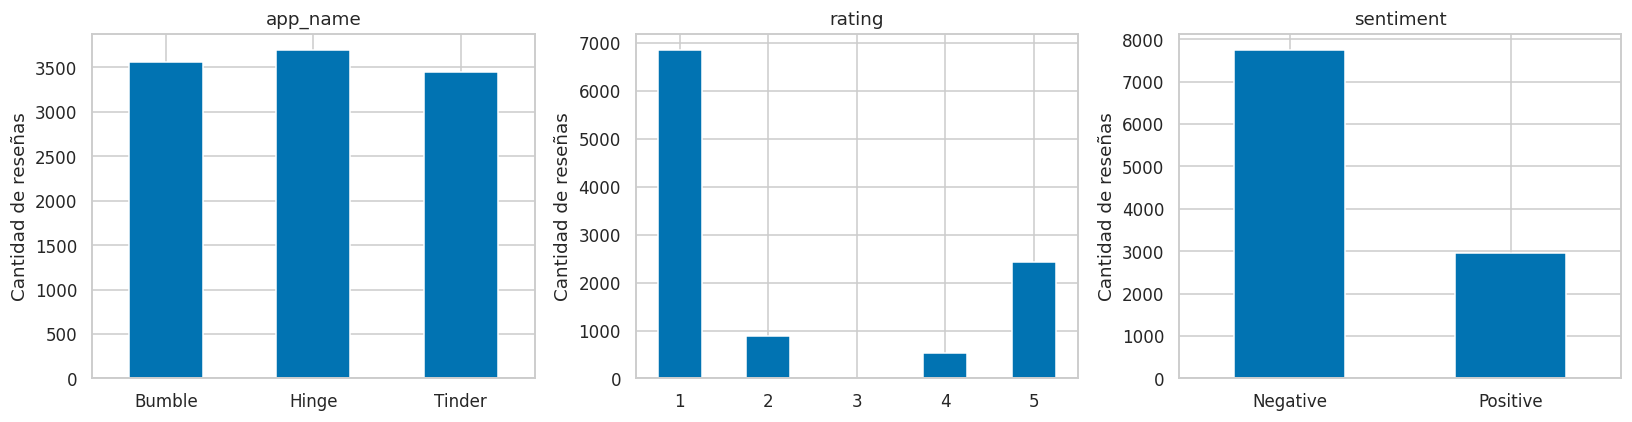

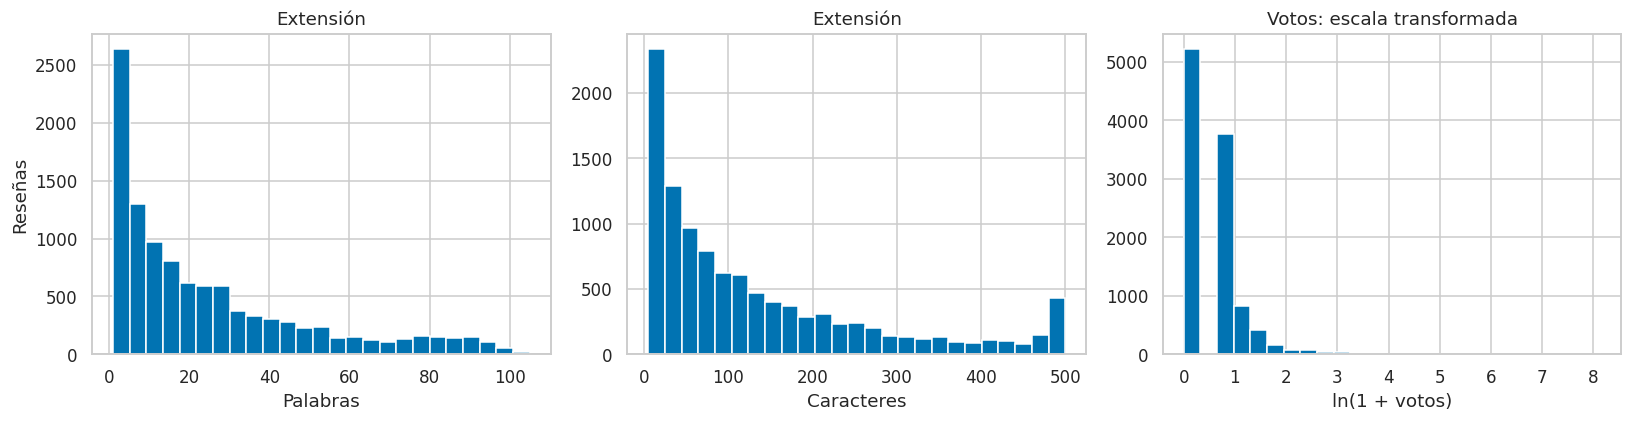

Porcentaje sin votos: 48.73
Reseñas con exactamente 500 caracteres: 53


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for col, ax, orden in [("app_name", axes[0], ["Bumble", "Hinge", "Tinder"]),
                        ("rating", axes[1], list(range(1, 6))),
                        ("sentiment", axes[2], ["Negative", "Positive"])]:
    conteo = df[col].value_counts().reindex(orden, fill_value=0)
    display(pd.DataFrame({"n": conteo, "%": (100*conteo/len(df)).round(2)}))
    conteo.plot.bar(ax=ax, rot=0)
    ax.set(title=col, ylabel="Cantidad de reseñas", xlabel="")
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df.review_word_count, bins=25)
axes[0].set(title="Extensión", xlabel="Palabras", ylabel="Reseñas")
axes[1].hist(df.review_char_len, bins=25)
axes[1].set(title="Extensión", xlabel="Caracteres")
axes[2].hist(np.log1p(df.thumbs_up), bins=25)
axes[2].set(title="Votos: escala transformada", xlabel="ln(1 + votos)")
plt.tight_layout()
plt.show()
print("Porcentaje sin votos:", round(100*df.thumbs_up.eq(0).mean(), 2))
print("Reseñas con exactamente 500 caracteres:", df.review_char_len.eq(500).sum())

**Interpretación:** hay 10.709 reseñas, con cantidades relativamente próximas por aplicación. El 72,28% está etiquetado como negativo. Las frecuencias exactas son 6.847 (1 estrella), 894 (2), 0 (3), 540 (4) y 2.428 (5). Es más preciso describir la concentración en 1 y 5 estrellas y la ausencia de 3 que inferir una forma continua a partir de un histograma.

La mediana de extensión es 16 palabras y 84 caracteres; la media de palabras es 24,92. Los votos presentan una fuerte asimetría: mediana 1, media 2,09 y máximo 3.433. El máximo observado de 500 caracteres aconseja investigar un posible límite de extracción o plataforma, sin darlo por confirmado.

### Cobertura temporal y comparabilidad

El comienzo del registro difiere entre aplicaciones. Los meses inicial y final pueden estar incompletos: el conteo mensual no equivale a actividad real o a crecimiento de la base de usuarios.

,min,max,count
app_name,,,
Bumble,2026-06-24 02:46:37,2026-09-13 19:13:23,3562
Hinge,2026-05-18 23:55:51,2026-09-13 19:19:36,3694
Tinder,2026-07-27 10:39:56,2026-09-13 19:47:29,3453


app_name,Bumble,Hinge,Tinder
mes,,,
2026-05,0,399,0
2026-06,241,988,0
2026-07,1651,964,300
2026-08,1184,968,2097
2026-09,486,375,1056


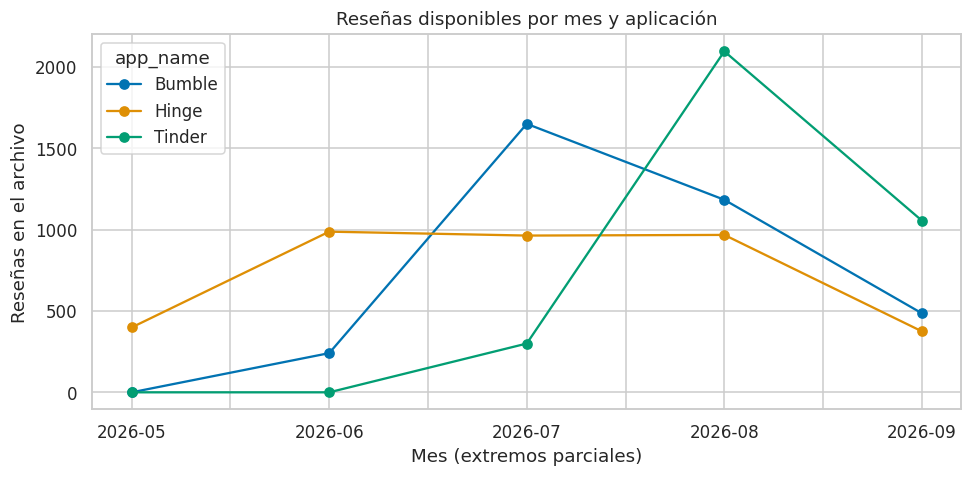

In [ ]:
cobertura = df.groupby("app_name").posted_at.agg(["min", "max", "count"])
display(cobertura)
mensual = pd.crosstab(df.mes, df.app_name)
display(mensual)
mensual.plot(marker="o", title="Reseñas disponibles por mes y aplicación")
plt.ylabel("Reseñas en el archivo")
plt.xlabel("Mes (extremos parciales)")
plt.tight_layout()
plt.show()

## 5. Hipótesis exploratorias

| Hipótesis | Pregunta y definición operativa |
|---|---|
| **H1.** Entre las reseñas con un solo tema detectado, las de fallas técnicas presentan menor proporción de valoraciones altas que las de monetización y las de autenticidad/estafas. | Comparar tres grupos mutuamente excluyentes según el diccionario. |
| **H2.** Las reseñas con dos o más temas detectados presentan menor proporción de valoraciones altas que las que tienen uno solo, incluso entre comentarios de extensión similar. | Comparar un tema frente a dos o más; excluir reseñas sin temas detectados de este contraste. |
| **H3.** Las diferencias de valoración entre aplicaciones se reducen al comparar una misma composición de temas detectados. | Comparar la brecha máximo–mínimo de tasas por app antes y después de una estandarización temática, sobre las mismas filas. |
| **H4.** Las reseñas que combinan monetización y autenticidad/estafas, sin fallas técnicas detectadas, presentan menor proporción de valoraciones altas que las que mencionan cada uno de esos temas por separado. | Contraste específico entre monetización sola, autenticidad sola y ambas, sin detección técnica. |

Estas hipótesis reemplazan las comparaciones iniciales de presencia/ausencia de cada tema. H2 examina acumulación en general; H4 estudia una combinación concreta y no constituye evidencia independiente de H2. Son exploratorias y se reformularon después de conocer el archivo: los resultados no son confirmatorios ni se usan para afirmar causas.

### Detección temática y revisión de ejemplos

Las expresiones regulares utilizan límites de palabra, ignoran mayúsculas y emplean un vocabulario principalmente inglés. No se traduce ni se lematiza el texto; términos compartidos, como `error`, pueden detectar otros idiomas. No se midió cobertura por idioma.

**Un solo tema significa un solo tema detectado**, no que el comentario trate únicamente de ese asunto. La ausencia de un término no demuestra ausencia del tema; una mención puede ser favorable, desfavorable o negada. `Scam` puede referirse a cobros o a la plataforma, no necesariamente a un perfil falso. Las etiquetas temáticas no verifican lo relatado.

Se conservan el diccionario y la revisión cualitativa de ejemplos. La palabra `glitchy`, omitida inicialmente, se incorporó antes de los cálculos. La revisión ilustra errores y ambigüedades, sin estimar precisión o recall del detector. Las diferencias se expresan en puntos porcentuales y se acompañan de tamaños de grupo.

In [ ]:
patrones = {
    "monetizacion": r"\b(?:pay|paid|paying|payment|payments|price|prices|pricing|cost|costs|expensive|subscription|subscriptions|subscribe|premium|money|refund|refunds|paywall|paywalls)\b",
    "fallas_tecnicas": r"\b(?:bug|bugs|buggy|crash|crashes|crashing|glitch|glitches|glitchy|freeze|freezes|freezing|loading|stuck|error|errors|lag|laggy)\b",
    "autenticidad_estafas": r"\b(?:fake|fakes|bot|bots|scam|scams|scammer|scammers|fraud|fraudulent|catfish|catfishing)\b"
}
df["valoracion_alta"] = df.rating.ge(4)
for tema, patron in patrones.items():
    df[tema] = df.review_text.str.contains(patron, case=False, regex=True, na=False)
    print(tema, "→", patron)
display(pd.DataFrame({"menciones_detectadas":df[list(patrones)].sum(),
                      "porcentaje_reseñas":100*df[list(patrones)].mean()}).round(2))
print("Reseñas que contienen términos de más de un tema:", df[list(patrones)].sum(axis=1).gt(1).sum())
# Tramos fijos; no se eliminan reseñas extensas.
df["tramo_palabras"] = pd.cut(df.review_word_count, [0,10,25,50,np.inf],
    labels=["1–10","11–25","26–50","51 o más"])
# Diccionarios y calidad son específicos del archivo recibido, no un etiquetado universal.

,menciones_detectadas,porcentaje_reseñas
monetizacion,2674,24.97
fallas_tecnicas,470,4.39
autenticidad_estafas,1064,9.94


monetizacion → \b(?:pay|paid|paying|payment|payments|price|prices|pricing|cost|costs|expensive|subscription|subscriptions|subscribe|premium|money|refund|refunds|paywall|paywalls)\b
fallas_tecnicas → \b(?:bug|bugs|buggy|crash|crashes|crashing|glitch|glitches|glitchy|freeze|freezes|freezing|loading|stuck|error|errors|lag|laggy)\b
autenticidad_estafas → \b(?:fake|fakes|bot|bots|scam|scams|scammer|scammers|fraud|fraudulent|catfish|catfishing)\b
Reseñas que contienen términos de más de un tema: 619


### Revisión cualitativa de ejemplos

Los índices corresponden al CSV original, con base cero. Son ejemplos examinados durante la revisión de reglas, con y sin detección; no una muestra independiente para medir rendimiento. Se conserva un caso de omisión inicial corregida y otro donde la mención es favorable, para hacer visibles los límites del enfoque.

In [ ]:
ejemplos = [
 ("monetizacion",4424,"Menciona pagar para ver likes; también se superpone con estafas."),
 ("monetizacion",3402,"Menciona funciones pagas, junto con perfiles falsos y actualización."),
 ("monetizacion",3608,"Menciona niveles pagos; valoración desfavorable del algoritmo."),
 ("monetizacion",6839,"Menciona pagar y también bots/estafas; temas superpuestos."),
 ("monetizacion",8845,"No menciona monetización de forma explícita."),
 ("monetizacion",8839,"Opinión favorable con crítica a otros usuarios; sin monetización explícita."),
 ("fallas_tecnicas",8615,"Configuración de distancia atascada; detección por stuck."),
 ("fallas_tecnicas",10200,"Texto en español detectado por error; no implica cobertura del español."),
 ("fallas_tecnicas",3943,"Menciona glitches del teléfono/app."),
 ("fallas_tecnicas",1057,"Describe un error al cargar discovery."),
 ("fallas_tecnicas",6075,"Cuestiona reportes y trato de la plataforma; sin falla técnica explícita clara."),
 ("fallas_tecnicas",6272,"Glitchy fue una omisión del diccionario inicial; incluida en la regla definitiva."),
 ("autenticidad_estafas",320,"Menciona bots y uso de datos."),
 ("autenticidad_estafas",10575,"Scam refiere a plataforma/cobros; no confirma perfiles falsos."),
 ("autenticidad_estafas",3632,"Menciona que eliminaron bots: mención favorable, no queja actual por bots."),
 ("autenticidad_estafas",6839,"Sospecha de bots y estafa; no prueba su existencia."),
 ("autenticidad_estafas",8155,"Critica upselling, matches e interfaz; sin mención explícita detectada de fraude."),
 ("autenticidad_estafas",1718,"Comentario favorable breve; sin mención de autenticidad.")
]
revision = pd.DataFrame([{"tema":t, "indice_csv":i, "detectado":bool(df.loc[i,t]),
    "texto":df.loc[i,"review_text"], "observacion_revision":nota} for t,i,nota in ejemplos])
with pd.option_context("display.max_colwidth", 240):
    display(revision)

,tema,indice_csv,detectado,texto,observacion_revision
0,monetizacion,4424,True,Never gives you the chance to swipe on someone who likes you unless you pay. Also seeing the same profile I swiped left on coming back up multiple times. I also only get like 5 right swipes per day. What a scam,Menciona pagar para ver likes; también se superpone con estafas.
1,monetizacion,3402,True,So so so many fake profiles. People being shown 4k miles away. Newest update is trash. Bring back the previous version so I can choose what I'm looking for. stop making everything paid,"Menciona funciones pagas, junto con perfiles falsos y actualización."
2,monetizacion,3608,True,algorithm is broken and paid tiers are ridiculous. one step removed from gambling.,Menciona niveles pagos; valoración desfavorable del algoritmo.
3,monetizacion,6839,True,Useless app. Have to pay to see who liked you and most likely its a bot so they can scam you 14 bucks,Menciona pagar y también bots/estafas; temas superpuestos.
4,monetizacion,8845,False,nomatter how great she is you will always download that app again looking for another one sad truth break the circle :(,No menciona monetización de forma explícita.
5,monetizacion,8839,False,"So far the best dating app I've come across. Tho, not perfect, as it attracts many women there who can't decide what they want in a relationship lol",Opinión favorable con crítica a otros usuarios; sin monetización explícita.
6,fallas_tecnicas,8615,True,Was working fine for years but is useless now because I can't change the circle for the maximum distance setting. It's stuck at 100+ miles. Why?,Configuración de distancia atascada; detección por stuck.
7,fallas_tecnicas,10200,True,No permite crear cuenta desde el inicio en cuanto colocas el número marca error,Texto en español detectado por error; no implica cobertura del español.
8,fallas_tecnicas,3943,True,app glitches on phone always deleting and re uploading . no matches. super swipe is useless,Menciona glitches del teléfono/app.
9,fallas_tecnicas,1057,True,Something Went Wrong error everytime I load discovery page with minimum age below 34. Tinder support refuse to help or do anything. Useless app and useless support team.,Describe un error al cargar discovery.


In [ ]:
temas = list(patrones)
df["n_temas"] = df[temas].sum(axis=1)
df["perfil_tematico"] = df[temas].astype(int).astype(str).agg("".join,axis=1)
etiquetas = {"monetizacion":"Monetización", "fallas_tecnicas":"Fallas técnicas", "autenticidad_estafas":"Autenticidad/estafas"}
def tabla_tasa(datos, grupo):
    return datos.groupby(grupo,observed=True).agg(n=("valoracion_alta","size"),altas=("valoracion_alta","sum"),altas_pct=("valoracion_alta",lambda x:100*x.mean()))
def grafico_tasas(tabla, titulo, ax=None):
    ax = tabla.altas_pct.plot.bar(ax=ax,rot=15,ylim=(0,100),ylabel="Valoraciones altas (%)",title=titulo)
    ax.set_xlabel("")
    for posicion, (_,fila) in enumerate(tabla.iterrows()):
        ax.text(posicion,float(fila.altas_pct)+1.5,f"{fila.altas_pct:.2f}%\nn={int(fila.n)}",ha="center",fontsize=8)
    return ax
cobertura = df.groupby("app_name").posted_at.agg(["min","max"])
inicio_comun = cobertura["min"].max().normalize()+pd.Timedelta(days=1)
fin_exclusivo = cobertura["max"].min().normalize()
comun = df[df.posted_at.ge(inicio_comun)&df.posted_at.lt(fin_exclusivo)].copy()
print("Período común de días completos:",inicio_comun.date(),"a",(fin_exclusivo-pd.Timedelta(days=1)).date())
print("Distribución del número de temas detectados:");display(tabla_tasa(df,"n_temas").round(2))
print("Tamaños por perfil (orden: monetización, técnica, autenticidad):")
display(pd.crosstab(df.perfil_tematico,df.app_name))

,n,altas,altas_pct
n_temas,,,
0,7135,2763,38.72
1,2955,197,6.67
2,604,8,1.32
3,15,0,0.00


app_name,Bumble,Hinge,Tinder
perfil_tematico,,,
000,2189,2547,2399
001,170,157,184
010,244,59,68
011,4,9,5
100,707,786,580
101,204,123,193
110,39,9,18
111,5,4,6


Período común de días completos: 2026-07-28 a 2026-09-12
Distribución del número de temas detectados:
Tamaños por perfil (orden: monetización, técnica, autenticidad):


### H1. Comparación entre tipos de tema

Se consideran solo reseñas con exactamente un indicador activado. El contraste requiere que la tasa de fallas técnicas sea menor que la de cada uno de los otros dos grupos. Se muestran también las tasas por app: el orden global puede no repetirse en todas las aplicaciones.

,n,altas,altas_pct
tema_unico,,,
Autenticidad/estafas,511,29,5.68
Fallas técnicas,371,13,3.50
Monetización,2073,155,7.48


n  altas_pct
app_name tema_unico                          
Bumble   Autenticidad/estafas  170       5.29
         Fallas técnicas       244       2.87
         Monetización          707       3.68
Hinge    Autenticidad/estafas  157       6.37
         Fallas técnicas        59       5.08
         Monetización          786       9.92
Tinder   Autenticidad/estafas  184       5.43
         Fallas técnicas        68       4.41
         Monetización          580       8.79

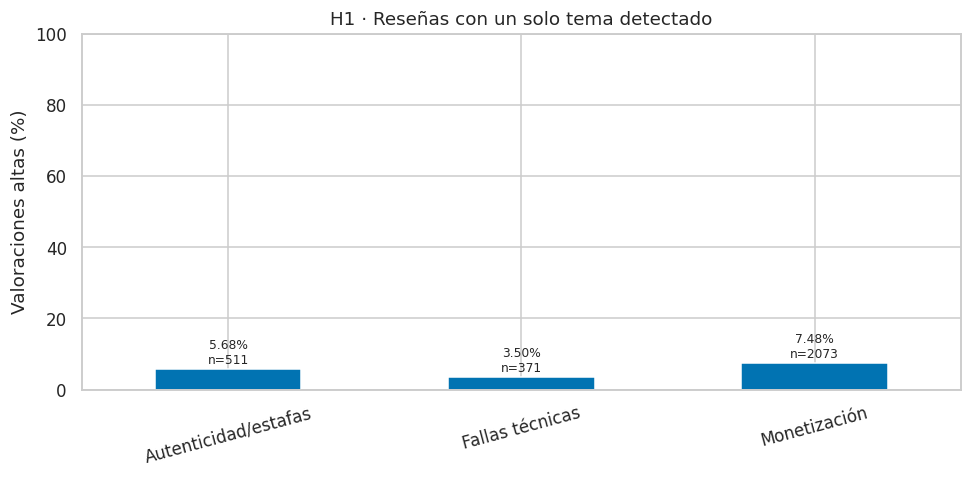

,app_name,tema_unico,review_text,rating
2547,Tinder,Autenticidad/estafas,worst experience all I'd are fake and non active,1
1821,Tinder,Autenticidad/estafas,The sipes are not local. Scam.,1
9042,Hinge,Autenticidad/estafas,fake accounts bots msging you to scam you lol,1
8051,Hinge,Fallas técnicas,error all time loading people,1
2187,Tinder,Fallas técnicas,The worst app ever Suddenly it stopped working I can't see any profile or text anyone But the app is working otherwise what kind of bug is that,1
640,Tinder,Fallas técnicas,"Buggy, Bad update July 2026 - it destroys all text formatting (spacing, carriage return, line feed) in all prompts including About Me section when clicking to edit. Horrible result of incompetent programmers & lack of testing. The app u...",1
8048,Hinge,Monetización,"profiles literally get moved into the ""stand outs"" while looking at them, which requires money. come on, if this is not a clear manipulation to force people to pay way too much for this.",1
7239,Hinge,Monetización,Messages would periodically disappear after getting a match. Brought it up multiple times with the helpdesk and they were not helpful in resolving the issue. I continued to get boilerplate replies to existing open troubletickets after t...,2
9489,Hinge,Monetización,Was ify at first thinking this would be another paysite. There are options to pay but I found an amazing person without spending a penny. Thank you for the site,5


Diferencia técnica - monetización, pp: -3.97
Diferencia técnica - autenticidad, pp: -2.17
H1: apoyo descriptivo global: True


In [ ]:
un_tema = df[df.n_temas.eq(1)].copy()
un_tema["tema_unico"] = un_tema[temas].idxmax(axis=1).map(etiquetas)
h1 = tabla_tasa(un_tema,"tema_unico")
display(h1.round(2))
h1_app = un_tema.groupby(["app_name","tema_unico"]).agg(n=("valoracion_alta","size"),altas_pct=("valoracion_alta",lambda x:100*x.mean()))
display(h1_app.round(2))
grafico_tasas(h1,"H1 · Reseñas con un solo tema detectado")
plt.tight_layout();plt.show()
print("Diferencia técnica - monetización, pp:",round(h1.loc["Fallas técnicas","altas_pct"]-h1.loc["Monetización","altas_pct"],2))
print("Diferencia técnica - autenticidad, pp:",round(h1.loc["Fallas técnicas","altas_pct"]-h1.loc["Autenticidad/estafas","altas_pct"],2))
print("H1: apoyo descriptivo global:",bool(h1.loc["Fallas técnicas","altas_pct"] < h1.drop(index="Fallas técnicas").altas_pct.min()))
# Ejemplos reproducibles: permiten examinar qué significa exclusividad de detección.
ejemplos_un_tema = pd.concat([un_tema[un_tema.tema_unico.eq(t)].sample(3,random_state=42) for t in h1.index])
with pd.option_context("display.max_colwidth",240):
    display(ejemplos_un_tema[["app_name","tema_unico","review_text","rating"]])

**Conclusión H1:** globalmente, las reseñas con fallas técnicas como único tema detectado tienen 3,50% de valoraciones altas (371 casos), frente a 7,48% para monetización (2.073) y 5,68% para autenticidad/estafas (511). Las diferencias son −3,97 y −2,17 puntos porcentuales, respectivamente. Hay apoyo descriptivo global y la tasa técnica es menor que la de cada uno de los otros temas en las tres aplicaciones. Los tamaños del grupo técnico son 244 en Bumble, 59 en Hinge y 68 en Tinder; esa desigualdad limita la estabilidad de las comparaciones.

La lectura de ejemplos muestra que el grupo de monetización puede incluir fallas descritas sin palabras del diccionario técnico. La conclusión se refiere a detección léxica, no a categorías semánticas exhaustivas ni a gravedad objetiva.

### H2. Acumulación de temas

Se comparan reseñas con un tema detectado frente a dos o más. Se excluyen las que no activan ningún indicador. Los tramos de longitud son fijos: 1–10, 11–25, 26–50 y 51 o más palabras. Los controles son descriptivos; no se considera que varios indicadores prueben la existencia de varios problemas reales.

,n,altas,altas_pct
grupo_acumulacion,,,
Un tema,2955,197,6.67
Dos o más,619,8,1.29


n  altas_pct
tramo_palabras grupo_acumulacion                
1–10           Dos o más           27       0.00
               Un tema            581       6.37
11–25          Dos o más          113       1.77
               Un tema            794       7.56
26–50          Dos o más          194       0.52
               Un tema            829       6.88
51 o más       Dos o más          285       1.75
               Un tema            751       5.73

n  altas_pct
app_name grupo_acumulacion                 
Bumble   Dos o más           252       0.79
         Un tema            1121       3.75
Hinge    Dos o más           145       1.38
         Un tema            1002       9.08
Tinder   Dos o más           222       1.80
         Un tema             832       7.69

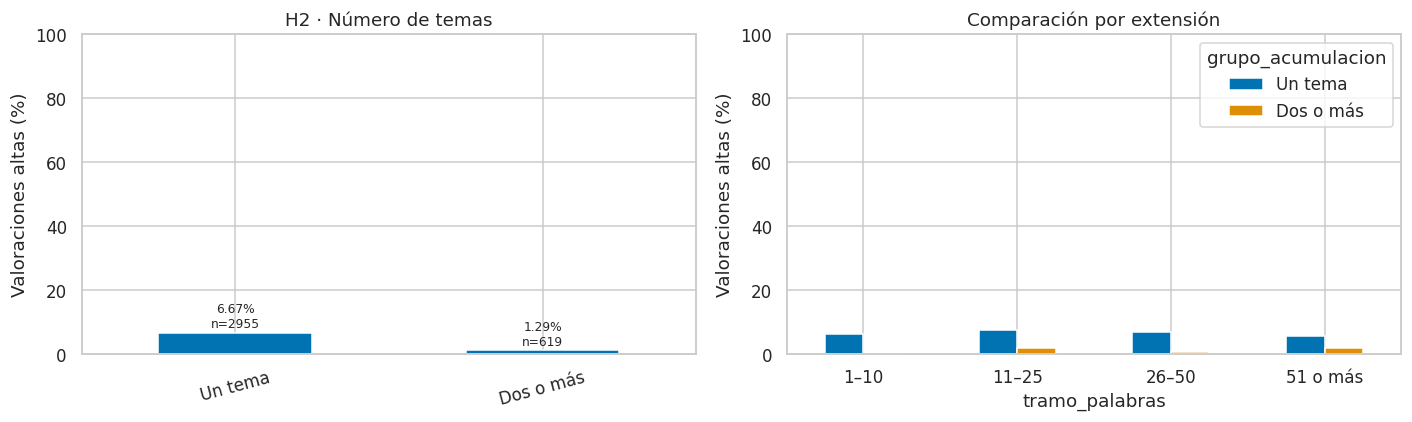

tramo_palabras
1–10       -6.37
11–25      -5.79
26–50      -6.36
51 o más   -3.97
dtype: float64

Diferencia dos o más - uno, pp: -5.37
Diferencias por longitud:


In [ ]:
acumulacion=df[df.n_temas.ge(1)].copy()
acumulacion["grupo_acumulacion"]=np.where(acumulacion.n_temas.eq(1),"Un tema","Dos o más")
h2=tabla_tasa(acumulacion,"grupo_acumulacion").reindex(["Un tema","Dos o más"])
display(h2.round(2))
h2_long=acumulacion.groupby(["tramo_palabras","grupo_acumulacion"],observed=True).agg(n=("valoracion_alta","size"),altas_pct=("valoracion_alta",lambda x:100*x.mean()))
h2_app=acumulacion.groupby(["app_name","grupo_acumulacion"]).agg(n=("valoracion_alta","size"),altas_pct=("valoracion_alta",lambda x:100*x.mean()))
display(h2_long.round(2));display(h2_app.round(2))
fig,axes=plt.subplots(1,2,figsize=(13,4))
grafico_tasas(h2,"H2 · Número de temas",axes[0])
h2_long.altas_pct.unstack().reindex(columns=["Un tema","Dos o más"]).plot.bar(ax=axes[1],rot=0,ylim=(0,100),title="Comparación por extensión",ylabel="Valoraciones altas (%)")
plt.tight_layout();plt.show()
print("Diferencia dos o más - uno, pp:",round(h2.loc["Dos o más","altas_pct"]-h2.loc["Un tema","altas_pct"],2))
print("Diferencias por longitud:");display((h2_long.altas_pct.unstack()["Dos o más"]-h2_long.altas_pct.unstack()["Un tema"]).round(2))

**Conclusión H2:** las reseñas con dos o más temas detectados tienen 1,29% de valoraciones altas (619 casos), frente a 6,67% cuando se detecta uno solo (2.955). La diferencia es −5,37 puntos porcentuales y mantiene su dirección en los cuatro tramos de longitud. Hay apoyo descriptivo para la acumulación de temas detectados; no se demuestra un efecto causal ni se controla completamente la extensión o el contenido.

### H3. Composición temática y diferencias entre aplicaciones

Se utiliza estandarización directa: para cada combinación de los tres indicadores se calcula la tasa de valoraciones altas de cada app y se ponderan todas las apps con una misma distribución temática, la distribución conjunta de los registros elegibles.

La medida de diferencia es la **brecha en puntos porcentuales entre la mayor y la menor tasa por app**. Se compara antes y después de estandarizar, siempre sobre las mismas filas. Para evitar tasas extremadamente inestables, el análisis principal exige al menos 20 reseñas de cada app en cada perfil. Se muestran sensibilidad sin ese umbral (mínimo 1) y en el período común.

Los umbrales son decisiones exploratorias, no criterios confirmatorios. El perfil `000` significa que no se detectaron estos tres temas; puede incluir muchos otros. La estandarización describe cómo cambian los promedios al igualar esta composición, sin identificar causas ni controlar todos los factores.

app_name,Bumble,Hinge,Tinder
perfil_tematico,,,
000,2189,2547,2399
001,170,157,184
010,244,59,68
100,707,786,580
101,204,123,193


perfil_tematico
000    0.6725
001    0.0482
010    0.0350
100    0.1954
101    0.0490
Name: proportion, dtype: float64

,n,tasa_cruda_pct,tasa_estandarizada_pct
app_name,,,
Bumble,3514,17.99,19.19
Hinge,3672,26.85,26.08
Tinder,3424,39.37,38.12


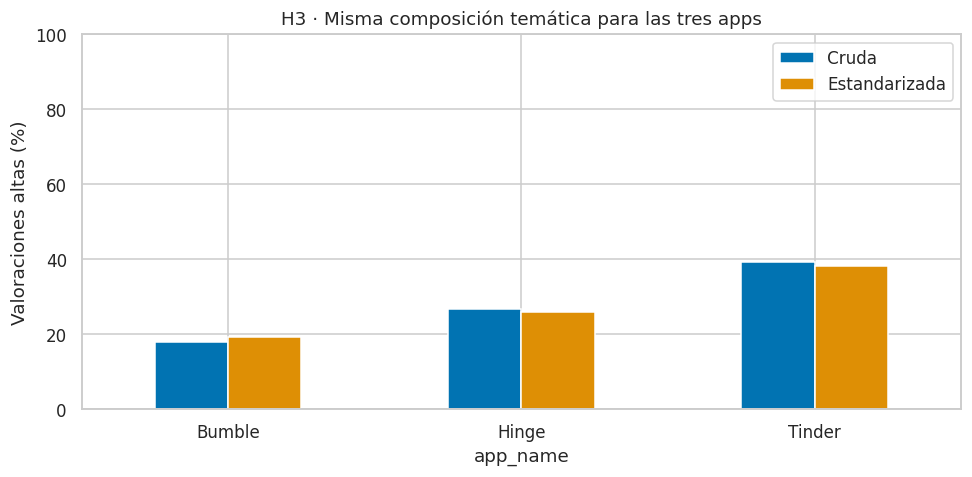

,escenario,n,brecha_cruda_pp,brecha_estandarizada_pp,reduccion_pp
0,"Completo, mínimo 1",10709,21.30,18.77,2.53
1,"Completo, mínimo 20",10610,21.38,18.93,2.46
2,"Período común, mínimo 20",6514,18.14,15.85,2.29


Perfiles elegibles y tamaños:
Pesos comunes:
Reseñas incluidas: 10610 de 10709 | Excluidas: 99
Brecha cruda: 21.38 pp; estandarizada: 18.93 pp; reducción: 2.46 pp (11.5% de la brecha cruda).


In [ ]:
def estandarizar(datos,minimo):
    conteos=pd.crosstab(datos.perfil_tematico,datos.app_name).reindex(columns=["Bumble","Hinge","Tinder"],fill_value=0)
    perfiles=conteos.index[conteos.min(axis=1).ge(minimo)]
    elegibles=datos[datos.perfil_tematico.isin(perfiles)]
    if elegibles.empty:
        raise ValueError("Sin perfiles comunes suficientes para estandarizar.")
    pesos=elegibles.perfil_tematico.value_counts(normalize=True)
    tasas=elegibles.groupby(["perfil_tematico","app_name"]).valoracion_alta.mean().unstack()
    ajustadas=100*tasas.mul(pesos,axis=0).sum()
    crudas=100*elegibles.groupby("app_name").valoracion_alta.mean()
    tabla=pd.DataFrame({"n":elegibles.groupby("app_name").size(),"tasa_cruda_pct":crudas,"tasa_estandarizada_pct":ajustadas})
    brecha_cruda=float(crudas.max()-crudas.min());brecha_est=float(ajustadas.max()-ajustadas.min())
    return tabla,pesos,conteos.loc[perfiles],len(elegibles),brecha_cruda,brecha_est
h3,pesos_h3,conteos_h3,n_h3,gap_crudo,gap_est=estandarizar(df,20)
print("Perfiles elegibles y tamaños:");display(conteos_h3)
print("Pesos comunes:");display(pesos_h3.sort_index().round(4))
display(h3.round(2))
print("Reseñas incluidas:",n_h3,"de",len(df),"| Excluidas:",len(df)-n_h3)
h3[["tasa_cruda_pct","tasa_estandarizada_pct"]].rename(columns={"tasa_cruda_pct":"Cruda","tasa_estandarizada_pct":"Estandarizada"}).plot.bar(rot=0,ylim=(0,100),ylabel="Valoraciones altas (%)",title="H3 · Misma composición temática para las tres apps")
plt.tight_layout();plt.show()
print(f"Brecha cruda: {gap_crudo:.2f} pp; estandarizada: {gap_est:.2f} pp; reducción: {gap_crudo-gap_est:.2f} pp ({100*(gap_crudo-gap_est)/gap_crudo:.1f}% de la brecha cruda).")
sensibilidad_h3=[]
for etiqueta,datos,minimo in [("Completo, mínimo 1",df,1),("Completo, mínimo 20",df,20),("Período común, mínimo 20",comun,20)]:
    tabla,pesos,cts,total,g0,g1=estandarizar(datos,minimo)
    sensibilidad_h3.append({"escenario":etiqueta,"n":total,"brecha_cruda_pp":g0,"brecha_estandarizada_pp":g1,"reduccion_pp":g0-g1})
display(pd.DataFrame(sensibilidad_h3).round(2))

**Conclusión H3:** con los perfiles que cumplen el umbral de 20 casos por app, se incluyen 10.610 reseñas y se excluyen 99. La brecha cruda es 21,38 puntos porcentuales y pasa a 18,93 al estandarizar: se reduce 2,46 puntos, aproximadamente 11,5% de la brecha inicial. Hay apoyo descriptivo en el análisis principal, pero la mayor parte de la diferencia permanece.

Las tasas estandarizadas son 19,19% para Bumble, 26,08% para Hinge y 38,12% para Tinder. Igualar estos indicadores no elimina las diferencias entre apps. La brecha también se reduce al incluir todos los perfiles (de 21,30 a 18,77 pp) y en el período común con el umbral de 20 (de 18,14 a 15,85 pp). La sensibilidad informa cuánto cambia el resultado al variar el soporte y las fechas; no se interpreta la reducción como porcentaje causalmente explicado.

### H4. Combinación de monetización y autenticidad/estafas

Se excluyen las reseñas con detección técnica y se comparan tres grupos: monetización sola, autenticidad/estafas sola y ambas. La hipótesis exige que la proporción de valoraciones altas del grupo combinado sea menor que la de cada grupo por separado.

Es una comparación específica de H2. Una tasa inferior en el grupo combinado no prueba una interacción estadística ni un efecto sinérgico: eso requeriría otro diseño y una definición de escala de interacción.

,n,altas,altas_pct
combinacion,,,
Monetización sola,2073,155,7.48
Autenticidad sola,511,29,5.68
Ambas,520,6,1.15


n  altas_pct
app_name combinacion                      
Bumble   Ambas              204       0.49
         Autenticidad sola  170       5.29
         Monetización sola  707       3.68
Hinge    Ambas              123       1.63
         Autenticidad sola  157       6.37
         Monetización sola  786       9.92
Tinder   Ambas              193       1.55
         Autenticidad sola  184       5.43
         Monetización sola  580       8.79

n  altas_pct
tramo_palabras combinacion                      
1–10           Ambas               25       0.00
               Autenticidad sola  181       3.31
               Monetización sola  310       9.35
11–25          Ambas               96       1.04
               Autenticidad sola  132       7.58
               Monetización sola  525       8.76
26–50          Ambas              170       0.59
               Autenticidad sola  116       9.48
               Monetización sola  616       6.49
51 o más       Ambas              229       1.75
               Autenticidad sola   82       2.44
               Monetización sola  622       6.43

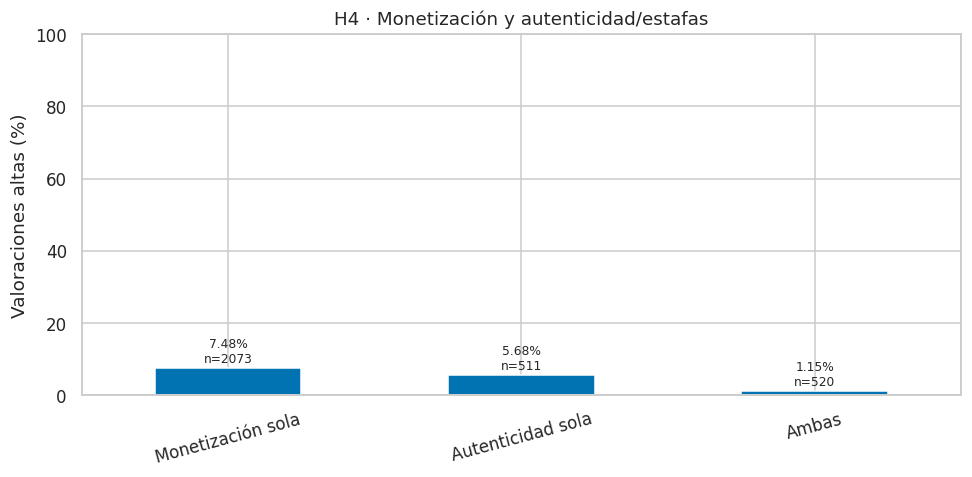

Ambas menos monetización sola, pp: -6.32
Ambas menos autenticidad sola, pp: -4.52
H4: apoyo descriptivo global: True


In [ ]:
h4_datos=df[(~df.fallas_tecnicas)&(df.monetizacion|df.autenticidad_estafas)].copy()
h4_datos["combinacion"]=np.select([h4_datos.monetizacion & h4_datos.autenticidad_estafas,h4_datos.monetizacion],["Ambas","Monetización sola"],default="Autenticidad sola")
h4=tabla_tasa(h4_datos,"combinacion").reindex(["Monetización sola","Autenticidad sola","Ambas"])
display(h4.round(2))
display(h4_datos.groupby(["app_name","combinacion"]).agg(n=("rating","size"),altas_pct=("valoracion_alta",lambda x:100*x.mean())).round(2))
display(h4_datos.groupby(["tramo_palabras","combinacion"],observed=True).agg(n=("rating","size"),altas_pct=("valoracion_alta",lambda x:100*x.mean())).round(2))
grafico_tasas(h4,"H4 · Monetización y autenticidad/estafas")
plt.tight_layout();plt.show()
print("Ambas menos monetización sola, pp:",round(h4.loc["Ambas","altas_pct"]-h4.loc["Monetización sola","altas_pct"],2))
print("Ambas menos autenticidad sola, pp:",round(h4.loc["Ambas","altas_pct"]-h4.loc["Autenticidad sola","altas_pct"],2))
print("H4: apoyo descriptivo global:",bool(h4.loc["Ambas","altas_pct"] < h4.drop(index="Ambas").altas_pct.min()))

**Conclusión H4:** cuando se detectan ambos temas, el porcentaje de valoraciones altas es 1,15% (520 casos), frente a 7,48% en monetización sola y 5,68% en autenticidad sola. Las diferencias son −6,32 y −4,52 puntos porcentuales. Hay apoyo descriptivo global al contraste específico.

Los grupos se definen por el vocabulario, no por problemas confirmados. Los desgloses permiten observar excepciones y celdas con pocos casos. Como H4 comparte registros y lógica con H2, no se presenta como un segundo experimento independiente ni como evidencia de causalidad.

## 6. EDA complementario y análisis multivariado

Se conserva la comparación general de valoraciones entre apps como descripción de contexto, sin convertir cualquier diferencia mínima en una hipótesis. Las tablas de H1, H2 y H4 comparan tema, valoración y app o extensión; H3 compara tasas con composición temática común.

,n,rating_medio,rating_mediano,satisfechos_pct
app_name,,,,
Bumble,3562,1.78,1.0,17.77
Hinge,3694,2.10,1.0,26.69
Tinder,3453,2.56,1.0,39.07


,n,satisfechos_pct
app_name,,
Bumble,1789,21.19
Hinge,1435,26.90
Tinder,3341,39.24


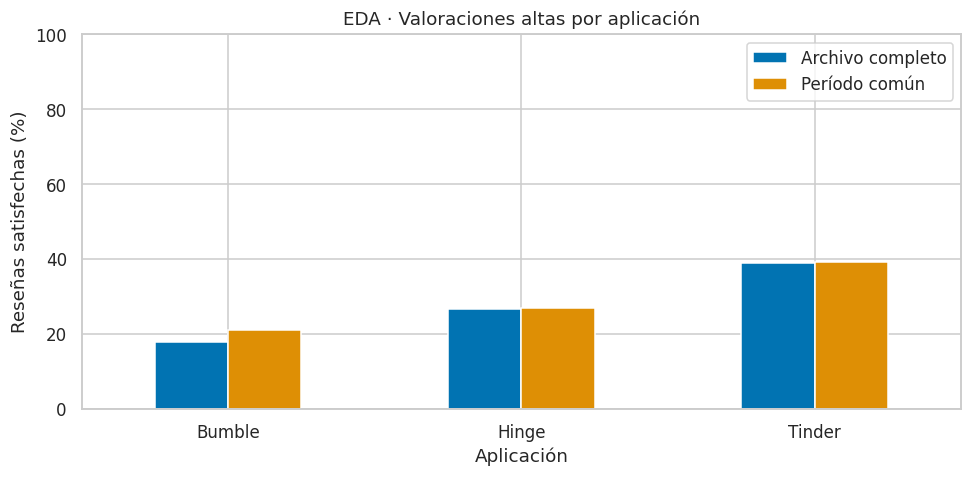

rating,1,2,3,4,5
app_name,,,,,
Bumble,72.04,10.19,0,3.68,14.09
Hinge,63.78,9.53,0,5.90,20.79
Tinder,55.75,5.18,0,5.53,33.54


Días completos comunes: 2026-07-28 a 2026-09-12


In [ ]:
resumen_app = df.groupby("app_name").agg(n=("rating", "size"),
    rating_medio=("rating", "mean"), rating_mediano=("rating", "median"),
    satisfechos_pct=("is_satisfied", lambda x: 100*x.mean()))
display(resumen_app.round(2))
inicio_comun = cobertura["min"].max().normalize() + pd.Timedelta(days=1)
fin_exclusivo = cobertura["max"].min().normalize()
comun = df.loc[df.posted_at.ge(inicio_comun) & df.posted_at.lt(fin_exclusivo)]
print("Días completos comunes:", inicio_comun.date(), "a", (fin_exclusivo-pd.Timedelta(days=1)).date())
sensibilidad = comun.groupby("app_name").agg(n=("rating", "size"), satisfechos_pct=("is_satisfied", lambda x:100*x.mean()))
display(sensibilidad.round(2))
pd.DataFrame({"Archivo completo": resumen_app.satisfechos_pct,
              "Período común": sensibilidad.satisfechos_pct}).plot.bar(rot=0)
plt.title("EDA · Valoraciones altas por aplicación")
plt.ylabel("Reseñas satisfechas (%)")
plt.ylim(0, 100)
plt.xlabel("Aplicación")
plt.tight_layout()
plt.show()
display(pd.crosstab(df.app_name, df.rating, normalize="index").reindex(columns=range(1,6), fill_value=0).mul(100).round(2))

En el archivo completo, las valoraciones altas son 39,07% en Tinder, 26,69% en Hinge y 17,77% en Bumble; en el período común, 39,24%, 26,90% y 21,19%. Los porcentajes corresponden a las reseñas disponibles, sin representar a todos los usuarios.

n  altas_pct
monetizacion fallas_tecnicas autenticidad_estafas                 
False        False           False                 7135      38.72
                             True                   511       5.68
             True            False                  371       3.50
                             True                    18       0.00
True         False           False                 2073       7.48
                             True                   520       1.15
             True            False                   66       3.03
                             True                    15       0.00

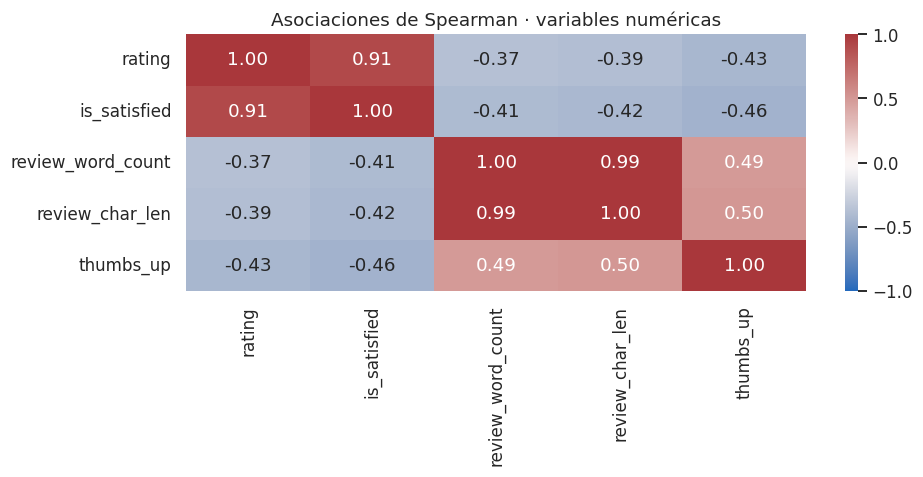

Pearson palabras/caracteres: 0.994


In [ ]:
display(df.groupby(list(patrones)).agg(n=("rating","size"),
    altas_pct=("valoracion_alta",lambda x:100*x.mean())).round(2))
columnas = ["rating","is_satisfied","review_word_count","review_char_len","thumbs_up"]
sns.heatmap(df[columnas].corr(method="spearman"),annot=True,fmt=".2f",cmap="vlag",vmin=-1,vmax=1)
plt.title("Asociaciones de Spearman · variables numéricas")
plt.tight_layout();plt.show()
print("Pearson palabras/caracteres:",round(df.review_word_count.corr(df.review_char_len),3))

**Interpretación:** rating y satisfacción expresan la misma agrupación observada. Palabras y caracteres presentan una relación muy alta y no aportan dimensiones independientes. Los votos son asimétricos y dependen de exposición y antigüedad no medidas; no son un indicador directo de veracidad. Las combinaciones de temas tienen tamaños distintos y no deben sumarse porcentajes de menciones como si fueran grupos excluyentes.



## 7. Síntesis de las cuatro hipótesis

| Hipótesis | Resultado principal | Alcance |
|---|---|---|
| H1. Tipo de tema | Técnica: 3,50% altas; autenticidad: 5,68%; monetización: 7,48%. | Apoyo global y mismo orden técnico frente a los otros temas en las tres apps. |
| H2. Acumulación | Dos o más: 1,29% altas; uno: 6,67%. | Apoyo global y mismo signo por longitud. |
| H3. Composición temática | Brecha de 21,38 a 18,93 pp; reducción de 2,46 pp. | Apoyo en el análisis principal; persiste una brecha considerable. |
| H4. Combinación específica | Ambas: 1,15% altas; monetización sola: 7,48%; autenticidad sola: 5,68%. | Apoyo global; contraste relacionado con H2, sin demostrar interacción causal. |

Las hipótesis aportan comparaciones de tipo, acumulación y composición, pero permanecen condicionadas al diccionario y a una muestra autoseleccionada. No se comprueba representatividad ni se estima causalidad. Las celdas pequeñas y las diferencias entre subgrupos deben considerarse al interpretar los promedios.

Se conserva la limpieza justificada: 10.709 filas, sin nulos ni duplicados exactos, conversión de fechas y preservación de textos repetidos y extremos. Los indicadores temáticos se añaden sin alterar el comentario original. La siguiente etapa clasifica valoraciones altas/bajas desde el texto, sin usar esos indicadores como etiquetas verdaderas de problemas ni como entradas adicionales.

## 8. Diseño del modelado y evaluación

### Objetivo, entradas y modelos

La variable objetivo es `valoracion_alta`, definida por rating ≥ 4 y auditada como equivalente a `is_satisfied`. La clase 0 representa rating 1–2 y la clase 1 rating 4–5. No hay clase neutral ni ejemplos de 3 estrellas; el modelo siempre elegirá una de las dos clases.

Se comparan **tres algoritmos de clasificación**, más una línea base mayoritaria:

| Modelo | Representación | Justificación |
|---|---|---|
| Naive Bayes multinomial | TF-IDF de palabras y pares de palabras | Referencia eficiente para clasificación de texto |
| Regresión logística | El mismo TF-IDF | Clasificador lineal regularizado e interpretable |
| SVM lineal | El mismo TF-IDF | Clasificación por margen adecuada para texto disperso |
| Línea base mayoritaria | Ignora contenido | Permite medir si aprender aporta frente a predecir siempre la clase más frecuente |

La representación y sus parámetros son comunes: hasta 20.000 términos, unigramas/bigramas, `min_df=2`, frecuencia sublineal. No se eliminan stopwords: negaciones como “not” pueden ser relevantes. No se traducen ni se lematizan reseñas y no se ajustan hiperparámetros buscando resultados del test. Se usan parámetros fijos de complejidad moderada; una futura optimización debe realizarse dentro de validación, no sobre prueba.

### Separación por grupos y prevención de fuga

Se construye una clave textual determinista: normalización Unicode NFKC, minúsculas y eliminación de espacios/puntuación. Reseñas con esa misma clave permanecen en la misma partición aunque tengan etiquetas diferentes. No se borran registros del EDA ni se resuelven etiquetas conflictivas por mayoría. Esto controla duplicados exactos y variantes superficiales; **no garantiza detectar paráfrasis o textos casi iguales**.

Se reserva aproximadamente un 20% mediante una partición de `StratifiedGroupKFold` con semilla 42; el 80% restante se usa para entrenamiento y validación cruzada de cuatro particiones por grupos. Las proporciones son aproximadas porque no se dividen grupos. Se audita la separación. El TF-IDF se aprende dentro de un `Pipeline` en cada partición de entrenamiento.

Este archivo ya se utilizó en el EDA y en ejecuciones preliminares del proyecto: el test es una reserva interna para comparar predicciones, no una evaluación externa completamente ciega. Se conserva el protocolo y no se ajustan los modelos ni sus parámetros según los resultados de prueba. La partición aleatoria por grupos estima desempeño sobre textos nuevos del mismo conjunto; no mide desempeño futuro, en otros idiomas ni en una app ausente del entrenamiento.

### Métrica y regla de selección

Se elige **F1 macro medio en validación cruzada**, para dar igual importancia a ambas clases. En caso de empate exacto, se prioriza menor dispersión y luego el nombre como desempate determinista. Se informan además accuracy, balanced accuracy y precisión, recall y F1 de cada clase. La exactitud aislada puede ocultar errores sobre la clase minoritaria.

El modelo se selecciona **antes de calcular las métricas de prueba**. Todos los candidatos se evalúan en la misma reserva. Sus resultados de prueba no modifican la selección ni se utilizan para ajustar umbrales. Las diferencias pequeñas no se interpretan como evidencia de superioridad estadística.
### Entorno y reproducibilidad

Las versiones de Python, pandas y NumPy utilizadas se imprimen en la celda de carga, y la versión de scikit-learn en la celda de modelado. El archivo de datos se identifica por su SHA-256. Para reproducir las particiones y métricas conviene utilizar las versiones registradas en esas salidas.

En esta ejecución se obtuvieron **8.618 reseñas de desarrollo y 2.091 de prueba**, sin grupos textuales compartidos. La semilla está fijada, pero para reproducir estas mismas particiones y métricas conviene conservar también las versiones del entorno. Las conclusiones se basan en las salidas de esta ejecución.

In [ ]:
import re
import unicodedata
import time
import sklearn
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, precision_recall_fscore_support, ConfusionMatrixDisplay)
print("scikit-learn:", sklearn.__version__)
SEMILLA = 42
X = df.review_text.astype(str).reset_index(drop=True)
y = df.valoracion_alta.astype(int).reset_index(drop=True)
def clave_texto(texto):
    texto = unicodedata.normalize("NFKC", texto).casefold()
    return re.sub(r"[\W_]+", "", texto, flags=re.UNICODE)
grupos = X.map(clave_texto)
# Se preservan claves vacías como un mismo grupo, sin perder observaciones.
auditoria_grupos = pd.DataFrame({"grupo": grupos, "y": y}).groupby("grupo").agg(n=("y","size"), etiquetas=("y","nunique"))
print("Grupos de texto:", grupos.nunique())
print("Grupos con etiquetas conflictivas:", auditoria_grupos.etiquetas.gt(1).sum())
separador = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
idx_desarrollo, idx_test = next(separador.split(X, y, grupos))
X_des, X_test = X.iloc[idx_desarrollo], X.iloc[idx_test]
y_des, y_test = y.iloc[idx_desarrollo], y.iloc[idx_test]
g_des, g_test = grupos.iloc[idx_desarrollo], grupos.iloc[idx_test]
assert not set(g_des).intersection(set(g_test))
cv = list(StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEMILLA).split(X_des, y_des, g_des))
for tr, va in cv:
    assert not set(g_des.iloc[tr]).intersection(set(g_des.iloc[va]))
    assert y_des.iloc[tr].nunique() == y_des.iloc[va].nunique() == 2
display(pd.DataFrame({"desarrollo_n": y_des.value_counts(), "prueba_n": y_test.value_counts(),
    "desarrollo_pct": y_des.value_counts(normalize=True)*100, "prueba_pct": y_test.value_counts(normalize=True)*100}).round(2))
print("Reseñas desarrollo / prueba:", len(X_des), len(X_test))
print("Grupos compartidos entre desarrollo y prueba: 0")
modelos = {
    "Naive Bayes": MultinomialNB(alpha=1.0),
    "Regresión logística": LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000, random_state=SEMILLA),
    "SVM lineal": LinearSVC(C=1.0, class_weight="balanced", random_state=SEMILLA, max_iter=5000)
}
def crear_pipeline(estimador):
    return Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1,2), min_df=2,
        max_features=20000, sublinear_tf=True)), ("modelo", clone(estimador))])
candidatos = {nombre: crear_pipeline(modelo) for nombre, modelo in modelos.items()}
candidatos["Línea base"] = crear_pipeline(DummyClassifier(strategy="most_frequent"))
filas_cv = []
for nombre, modelo in candidatos.items():
    resultado = cross_validate(modelo, X_des, y_des, cv=cv,
        scoring={"f1_macro":"f1_macro", "balanced_accuracy":"balanced_accuracy", "accuracy":"accuracy"}, n_jobs=1)
    filas_cv.append({"modelo": nombre, "f1_macro_cv": resultado["test_f1_macro"].mean(),
        "desvio_f1_cv": resultado["test_f1_macro"].std(ddof=1),
        "balanced_accuracy_cv": resultado["test_balanced_accuracy"].mean(),
        "accuracy_cv": resultado["test_accuracy"].mean()})
tabla_cv = pd.DataFrame(filas_cv).set_index("modelo")
# Para un empate exacto completo se ordena alfabéticamente antes de aplicar los criterios.
elegibles = tabla_cv.drop(index="Línea base").sort_index().sort_values(["f1_macro_cv","desvio_f1_cv"], ascending=[False,True], kind="stable")
nombre_elegido = elegibles.index[0]
display(tabla_cv.round(4))
print("Modelo seleccionado por validación (antes del test):", nombre_elegido)
print("La desviación entre folds describe variabilidad; no es un intervalo de confianza.")

scikit-learn: 1.6.1
Grupos de texto: 9785
Grupos con etiquetas conflictivas: 22


,desarrollo_n,prueba_n,desarrollo_pct,prueba_pct
valoracion_alta,,,,
0,6213,1528,72.09,73.08
1,2405,563,27.91,26.92


Reseñas desarrollo / prueba: 8618 2091
Grupos compartidos entre desarrollo y prueba: 0


,f1_macro_cv,desvio_f1_cv,balanced_accuracy_cv,accuracy_cv
modelo,,,,
Naive Bayes,0.8110,0.0088,0.7729,0.8714
Regresión logística,0.8951,0.0114,0.8859,0.9179
SVM lineal,0.8991,0.0058,0.8925,0.9204
Línea base,0.4190,0.0052,0.5000,0.7212


Modelo seleccionado por validación (antes del test): SVM lineal
La desviación entre folds describe variabilidad; no es un intervalo de confianza.


## 9. Comparación en prueba y diagnóstico de errores

Cada modelo se reentrena en todo el conjunto de desarrollo. Las métricas se calculan sobre las mismas reseñas reservadas. La regla de decisión sigue siendo la selección previa por validación. No se usa el test para buscar parámetros o cambiar el modelo.

,accuracy,balanced_accuracy,f1_macro,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,segundos_fit_y_predict
modelo,,,,,,,,,,
Naive Bayes,0.8847,0.7905,0.8295,0.8671,0.9948,0.9265,0.9763,0.5861,0.7325,0.6800
Regresión logística,0.9254,0.8996,0.9041,0.9432,0.9555,0.9493,0.8748,0.8437,0.8590,0.7210
SVM lineal,0.9254,0.9007,0.9043,0.9443,0.9542,0.9492,0.8720,0.8472,0.8595,0.5958
Línea base,0.7308,0.5000,0.4222,0.7308,1.0000,0.8444,0.0000,0.0000,0.0000,0.5890


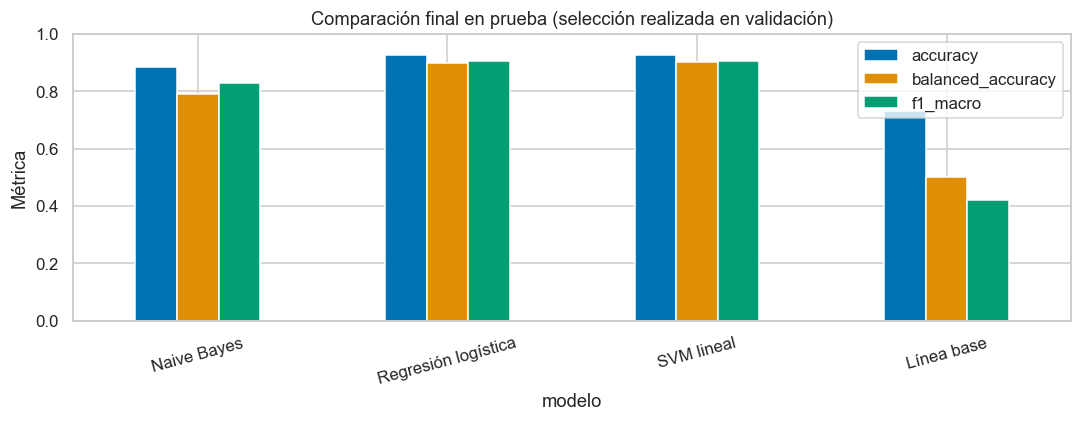

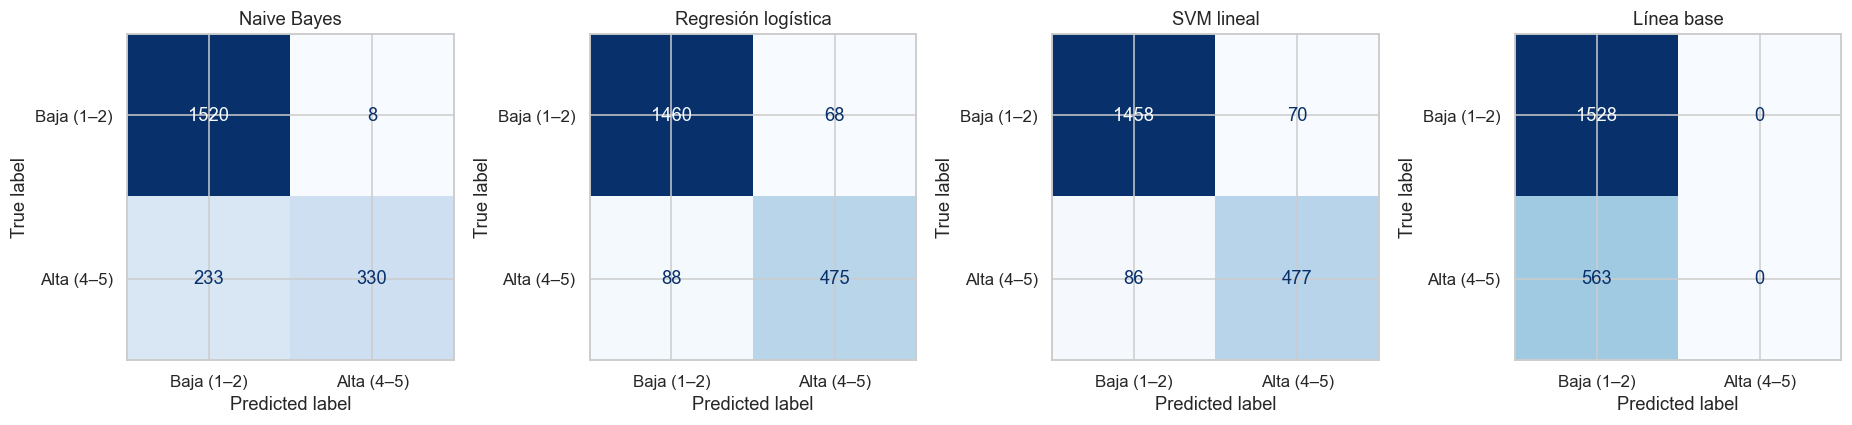

Informe del modelo elegido: SVM lineal
              precision    recall  f1-score   support

  Baja (1–2)      0.944     0.954     0.949      1528
  Alta (4–5)      0.872     0.847     0.859       563

    accuracy                          0.925      2091
   macro avg      0.908     0.901     0.904      2091
weighted avg      0.925     0.925     0.925      2091



,app,n,f1_macro,recall_satisfecha
0,Bumble,718,0.9126,0.8462
1,Hinge,706,0.8942,0.8579
2,Tinder,667,0.8981,0.8403


Ejemplos de errores (primeros en orden de prueba, sin selección manual):


,texto,real,prediccion
17,Error 40311,0,1
30,it freezes from time to time,1,0
51,cannot open my account,1,0
64,I'm enjoying every single moment on tinder,1,0
81,"I have not used this app to much this year, ev...",1,0
96,it very confusing I do not know if I need to p...,0,1
97,i have been logged out since 3days now after s...,1,0
99,why my phone can not used tinder,1,0


In [ ]:
filas_test, predicciones, entrenados = [], {}, {}
for nombre, candidato in candidatos.items():
    inicio = time.perf_counter()
    modelo = clone(candidato).fit(X_des, y_des)
    pred = modelo.predict(X_test)
    precision, recall, f1, soporte = precision_recall_fscore_support(y_test, pred, labels=[0,1], zero_division=0)
    filas_test.append({"modelo":nombre, "accuracy":accuracy_score(y_test,pred),
        "balanced_accuracy":balanced_accuracy_score(y_test,pred), "f1_macro":f1_score(y_test,pred,average="macro"),
        "precision_0":precision[0], "recall_0":recall[0], "f1_0":f1[0],
        "precision_1":precision[1], "recall_1":recall[1], "f1_1":f1[1],
        "segundos_fit_y_predict":time.perf_counter()-inicio})
    predicciones[nombre], entrenados[nombre] = pred, modelo
tabla_test = pd.DataFrame(filas_test).set_index("modelo")
display(tabla_test.round(4))
fig, ax = plt.subplots(figsize=(10,4))
tabla_test[["accuracy","balanced_accuracy","f1_macro"]].plot.bar(ax=ax,rot=15)
ax.set(title="Comparación final en prueba (selección realizada en validación)", ylabel="Métrica", ylim=(0,1))
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1,4,figsize=(17,4))
for ax, nombre in zip(axes, candidatos):
    ConfusionMatrixDisplay.from_predictions(y_test, predicciones[nombre], labels=[0,1],
        display_labels=["Baja (1–2)","Alta (4–5)"], ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nombre)
plt.tight_layout(); plt.show()
print("Informe del modelo elegido:", nombre_elegido)
print(classification_report(y_test, predicciones[nombre_elegido], target_names=["Baja (1–2)","Alta (4–5)"], digits=3, zero_division=0))
por_app=[]
apps_test=df.app_name.iloc[idx_test].reset_index(drop=True)
for app in sorted(apps_test.unique()):
    mascara=apps_test.eq(app).to_numpy()
    por_app.append({"app":app, "n":int(mascara.sum()), "f1_macro":f1_score(y_test.to_numpy()[mascara],predicciones[nombre_elegido][mascara],average="macro",labels=[0,1],zero_division=0),
        "recall_satisfecha":precision_recall_fscore_support(y_test.to_numpy()[mascara],predicciones[nombre_elegido][mascara],labels=[0,1],zero_division=0)[1][1]})
display(pd.DataFrame(por_app).round(4))
errores = pd.DataFrame({"texto":X_test.to_numpy(), "real":y_test.to_numpy(), "prediccion":predicciones[nombre_elegido]})
print("Ejemplos de errores (primeros en orden de prueba, sin selección manual):")
display(errores.loc[errores.real.ne(errores.prediccion)].head(8))

**Lectura de las métricas:** en la matriz, filas son clases reales y columnas son predichas. Una predicción incorrecta de clase alta deja pasar una reseña de baja calificación; una predicción incorrecta de clase baja envía a revisión una reseña de alta calificación. El recall de clase 0 interesa para detectar insatisfacción y el de clase 1 evita ignorar la minoría. Macro-F1 resume el compromiso entre ambas.

Los ejemplos de error pueden corresponder a ambigüedad, ironía, texto breve o desacuerdo entre texto y rating. Son posibilidades de interpretación, no un diagnóstico confirmado sin revisión manual. Los resultados por app describen subconjuntos del mismo test, no una validación de transferencia a apps nuevas.

## 10. Selección y conclusión final calculada

La siguiente salida incorpora las métricas obtenidas en esta ejecución. El modelo elegido no se cambia si otro candidato supera su puntaje en la reserva.

In [ ]:
mejor_cv=tabla_cv.loc[nombre_elegido]
resultado_final=tabla_test.loc[nombre_elegido]
base=tabla_test.loc["Línea base"]
print(f"Seleccionamos {nombre_elegido} por su F1 macro medio de validación: {mejor_cv.f1_macro_cv:.4f} (desvío entre folds: {mejor_cv.desvio_f1_cv:.4f}).")
print(f"En prueba: F1 macro={resultado_final.f1_macro:.4f}; balanced accuracy={resultado_final.balanced_accuracy:.4f}; accuracy={resultado_final.accuracy:.4f}.")
print(f"Recall no satisfecha={resultado_final.recall_0:.4f}; recall satisfecha={resultado_final.recall_1:.4f}.")
print(f"Línea base en prueba: F1 macro={base.f1_macro:.4f}; mejora absoluta={resultado_final.f1_macro-base.f1_macro:.4f}.")
print("La elección corresponde al mejor candidato con estas particiones y parámetros; no demuestra que sea el mejor algoritmo posible.")

Seleccionamos SVM lineal por su F1 macro medio de validación: 0.8991 (desvío entre folds: 0.0058).
En prueba: F1 macro=0.9043; balanced accuracy=0.9007; accuracy=0.9254.
Recall no satisfecha=0.9542; recall satisfecha=0.8472.
Línea base en prueba: F1 macro=0.4222; mejora absoluta=0.4821.
La elección corresponde al mejor candidato con estas particiones y parámetros; no demuestra que sea el mejor algoritmo posible.


### Interpretación de la selección

En esta ejecución se selecciona **SVM lineal** porque obtiene el mayor F1 macro medio en validación: **0,8991**, frente a **0,8951** de regresión logística y **0,8110** de Naive Bayes. Su desviación entre folds es 0,0058. La diferencia con regresión logística es pequeña y no demuestra superioridad estadística.

En las **2.091 reseñas de prueba**, SVM obtiene F1 macro **0,9043**, exactitud **0,9254** y balanced accuracy **0,9007**. Su recall es **0,9542** para valoraciones bajas y **0,8472** para altas. La matriz contiene 1.458 bajas y 477 altas clasificadas correctamente; se confunden 70 bajas como altas y 86 altas como bajas. El modelo reconoce mejor la clase de valoración baja que la alta.

Regresión logística alcanza la misma exactitud redondeada (0,9254) y un F1 macro muy cercano (0,9041). No se cambia la elección según esos resultados: ambos son candidatos competitivos, y se mantiene el criterio previo de validación. La línea base obtiene F1 macro 0,4222, frente a 0,9043 de SVM. La elección corresponde a las configuraciones y particiones evaluadas; no se realizó una búsqueda exhaustiva de hiperparámetros.

Las ponderaciones de clase de logística y SVM ayudan a dar importancia a la minoría durante el ajuste; son parte de sus configuraciones, no una garantía de mejor rendimiento. Naive Bayes conserva sus probabilidades previas aprendidas del entrenamiento. La comparación corresponde a estas configuraciones concretas.

### ¿Qué términos utiliza el clasificador?

Se muestran términos con mayor peso hacia cada clase cuando el modelo seleccionado permite extraer coeficientes lineales. Se ajustó exclusivamente con desarrollo. Estos pesos describen cómo decide el modelo sobre TF-IDF: no indican que una palabra cause satisfacción o insatisfacción, ni verifican los motivos de la reseña.

In [ ]:
modelo_elegido = entrenados[nombre_elegido]
vectorizador = modelo_elegido.named_steps["tfidf"]
estimador = modelo_elegido.named_steps["modelo"]
if hasattr(estimador, "coef_"):
    terminos = vectorizador.get_feature_names_out()
    pesos = estimador.coef_[0]
    hacia_baja = np.argsort(pesos)[:12]
    hacia_alta = np.argsort(pesos)[-12:][::-1]
    display(pd.DataFrame({"termino_hacia_baja":terminos[hacia_baja],
                          "peso_baja":pesos[hacia_baja],
                          "termino_hacia_alta":terminos[hacia_alta],
                          "peso_alta":pesos[hacia_alta]}).round(3))
else:
    print("El modelo elegido no tiene coeficientes lineales directamente comparables.")
print("SVM no ofrece probabilidades calibradas en esta configuración; sus salidas de clase no deben presentarse como porcentajes de confianza.")

,termino_hacia_baja,peso_baja,termino_hacia_alta,peso_alta
0,not,-2.441,not bad,2.603
1,worst,-2.376,met,2.603
2,money,-1.984,best,1.976
3,scam,-1.940,amazing,1.930
4,useless,-1.897,but,1.829
5,nothing,-1.806,beautiful,1.816
6,no,-1.781,good,1.811
7,banned,-1.765,wonderful,1.719
8,sucks,-1.646,found,1.590
9,even,-1.593,no bad,1.536


SVM no ofrece probabilidades calibradas en esta configuración; sus salidas de clase no deben presentarse como porcentajes de confianza.


## 11. Conclusión general del proyecto

Las reseñas permiten estudiar valoraciones espontáneas, sin equipararlas a una encuesta representativa. Las estrellas y las etiquetas del archivo no son mediciones independientes: positivo/negativo y satisfecho/no satisfecho coinciden con la agrupación de calificaciones. El texto aporta información distinta, aunque puede ser ambiguo o discrepar con las estrellas.

Las hipótesis reformuladas comparan tipos de tema, acumulación, composición temática de las aplicaciones y la combinación de monetización con autenticidad/estafas. Los resultados principales brindan apoyo descriptivo bajo las reglas utilizadas. La estandarización temática reduce solo una parte de la brecha entre apps; H2 y H4 son contrastes relacionados, no evidencias independientes. Los desgloses y ejemplos delimitan la interpretación, sin atribuir causas ni tratar toda mención como queja.

La clasificación complementa ese análisis: los tres modelos aprenden a recuperar la valoración a partir del texto y se comparan mediante el mismo protocolo, con un control de grupos textuales y una línea base. Se selecciona SVM lineal por F1 macro medio de validación (0,8991). En prueba obtiene F1 macro 0,9043 y exactitud 92,54%; la ventaja respecto de regresión logística es pequeña. Estos resultados superan la línea base mayoritaria, sin demostrar desempeño en datos externos. La selección se limita a los candidatos, parámetros y particiones evaluados.

**Aplicación de los resultados:** si ya se conocen las estrellas, no hace falta un modelo para agruparlas. El prototipo podría servir para explorar comentarios sin calificación o priorizar revisión humana, pero la transferencia a esos textos requiere evaluación adicional. No se predice satisfacción psicológica, compatibilidad ni éxito en citas.

### Limitaciones predictivas y próximos pasos

La separación por claves normalizadas controla coincidencias textuales y variantes superficiales, pero no garantiza detectar paráfrasis, textos casi iguales o el mismo usuario. No hay una evaluación temporal independiente, fuera de muestra por app ni externa; tampoco se midió transferencia por idioma. El archivo ya fue explorado durante el proyecto. La ausencia de 3 estrellas limita el alcance de la clasificación binaria.

Para ampliar el estudio se propone evaluar una muestra externa o temporal, revisar manualmente los desacuerdos entre texto y rating e incorporar controles de similitud semántica. Estas validaciones quedan fuera del alcance del prototipo académico presentado.

## Referencias

- `samartalwar`. *Dating App Reviews: Tinder, Bumble & Hinge*. Kaggle. Dataset y descripción de su procedencia: https://www.kaggle.com/datasets/samartalwar/dating-app-reviews-tinder-bumble-and-hinge/data
- Devra AI. *Dating App Reviews: Analysis and Prediction*. Kaggle. Notebook consultado como antecedente. Su modelo utiliza rating para predecir is_satisfied; en este trabajo se excluye esa entrada debido a la equivalencia observada entre las variables: https://www.kaggle.com/code/devraai/dating-app-reviews-analysis-and-prediction/notebook
- scikit-learn. *StratifiedGroupKFold*: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html
- scikit-learn. *Extracción de características textuales*: https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction
- scikit-learn. *Métricas de evaluación*: https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=9e05b266-ed28-4258-ae74-d62cc7e3b92d' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>